# 09 — Searching the collection with words (optional part 2)

The optional part of the brief: a visitor types what they are looking for ("a stormy sea", "Mount Fuji"), the guide shows the closest works of the collection and answers with a short chat reply.

- **The search** uses CLIP (`museum/search.py`), an open model that puts images and texts in the same space, so a sentence can be compared with a painting. It isn't trained on our images at all.
- **The reply** (`museum/chat.py`) is written from what we actually know about the works found: their style, and their artist and genre when `metadata.csv` has them. Either fixed sentences (a template), or a small language model whose reply is checked against those facts.

1. Zero-shot style recognition: how good is CLIP at our task with no training?
2. Searching for a style.
3. Searching for content, judged by eye.
4. Queries the collection can't answer.
5. The chat reply: template vs language model.
6. Cost against the director's three criteria.

**Data rules.** Only the train and validation images are searchable (1,275 works). The test set stays out, like everywhere except `07_comparison`. Every accuracy here is on validation.

Needs the optional requirements: `pip install -r requirements-search.txt`. The first run downloads the two models (about 600 MB and 1 GB).

In [1]:
import json
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from transformers.utils import logging as hf_logging

sys.path.insert(0, "../src")
from museum.chat import LLM_ID, LLMReplier, check_reply, reply, template_reply
from museum.data import CLASSES, IMAGE_DIR, ROOT, get_arrays
from museum.evaluation import benchmark_latency, plot_confusion, total_parameters, wilson_ci
from museum.guide import DISPLAY_NAMES
from museum.search import MODEL_ID, STYLE_PROMPT, ClipEncoder, Collection, style_scores

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: fewer replies and shorter timings
FIG_DIR = ROOT / "results" / "figures"
NAMES = [DISPLAY_NAMES.get(c, c) for c in CLASSES]
hf_logging.disable_progress_bar()

start = time.perf_counter()
encoder = ClipEncoder()
collection = Collection.load(encoder)   # embeds the images once, then reads results/features/clip_*.npy
print(f"{MODEL_ID}: {len(collection.table)} searchable works {collection.table['split'].value_counts().to_dict()}, "
      f"embeddings {collection.embeddings.shape}, ready in {time.perf_counter() - start:.0f} s")

W1021 11:13:14.435000 48155 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


laion/CLIP-ViT-B-32-laion2B-s34B-b79K: 1275 searchable works {'train': 1050, 'val': 225}, embeddings (1275, 512), ready in 11 s


## 1. Zero-shot style recognition (validation)

**How it works.** CLIP was trained on 2 billion images from the web with their captions: it learned to give an image and its caption close embeddings, and an image and someone else's caption distant ones (contrastive training). So to classify without training, we write one sentence per style, like "a painting in the Pop Art style", and each image gets the style whose sentence is closest.

We tried three phrasings. The fine-tuned ResNet18 (`results/resnet_finetune.json`, trained on our 1,050 images) is the reference, on the same 225 validation images.

In [2]:
val = (collection.table["split"] == "val").to_numpy()
E_val, y_val = collection.embeddings[val], collection.table.loc[val, "label_idx"].to_numpy()
PROMPTS = ["a {} painting", STYLE_PROMPT, "an artwork, {} style"]
predictions = {prompt: style_scores(encoder, E_val, prompt).argmax(axis=1) for prompt in PROMPTS}

rows = []
for prompt, pred in predictions.items():
    right = int((pred == y_val).sum())
    rows.append({"model": f'CLIP zero-shot, "{prompt}"', "val accuracy": right / len(y_val),
                 "95 % CI": "{:.3f}-{:.3f}".format(*wilson_ci(right, len(y_val)))})
resnet = json.loads((ROOT / "results" / "resnet_finetune.json").read_text())
right = round(resnet["val_acc"] * len(y_val))
rows.append({"model": "fine-tuned ResNet18 (trained on our images)", "val accuracy": resnet["val_acc"],
             "95 % CI": "{:.3f}-{:.3f}".format(*wilson_ci(right, len(y_val)))})
pd.DataFrame(rows).set_index("model").round(3)

,val accuracy,95 % CI
model,,
"CLIP zero-shot, ""a {} painting""",0.853,0.801-0.894
"CLIP zero-shot, ""a painting in the {} style""",0.876,0.826-0.912
"CLIP zero-shot, ""an artwork, {} style""",0.844,0.791-0.886
fine-tuned ResNet18 (trained on our images),0.862,0.811-0.901


In [3]:
fig = plot_confusion(y_val, predictions[STYLE_PROMPT], NAMES, FIG_DIR / "09_zero_shot_val_confusion.png",
                     title=f'CLIP zero-shot, "{STYLE_PROMPT}" (validation)')
plt.show()

**What we see**
- **With no training at all, CLIP gets 84–88 % of the validation images right**, depending on how the sentence is written. Our fine-tuned ResNet18 gets 86.2 % on the same images. The four confidence intervals overlap a lot, so with 225 images we can't say one is better than the other.
- **The phrasing alone moves the score by 3 points** (about 7 images).
- **Its weak style is Pop Art** (64 %): 10 of the 45 Pop Art images are called Cubism. Ukiyo-e is perfect and Baroque almost.

**Why we don't say "CLIP is as good as our model"**
- **We picked the best phrasing on these same 225 images**, so 87.6 % is a bit optimistic. The other two (85.3 % and 84.4 %) are more honest numbers.
- **CLIP has probably seen some of these paintings already.** LAION-2B was collected from the web, and WikiArt images are on the web with captions like "Impressionism". So this isn't a clean test on unseen images, and we have no way to check which ones it saw.
- **It was never run on the test set** (only the four candidates are, in `07_comparison`), so it can't be compared with the ResNet's 84.0 % on test.
- **It doesn't fit the kiosk** anyway (section 6).

## 2. Searching for a style

The visitor types the style itself. **Precision@10** is the share of the 10 first results that really have that style. Here the whole searchable collection (train + validation) is used: CLIP never trained on any of it.

In [4]:
rows = []
for label, name in zip(CLASSES, NAMES, strict=True):
    found = collection.search(STYLE_PROMPT.format(name), k=10)
    rows.append({"query": STYLE_PROMPT.format(name), "precision@10": (found["label"] == label).mean(),
                 "styles in the 10 results": found["label"].map(DISPLAY_NAMES).fillna(found["label"]).value_counts().to_dict()})
style_queries = pd.DataFrame(rows).set_index("query")
print(f"mean precision@10: {style_queries['precision@10'].mean():.2f}")
style_queries

mean precision@10: 1.00


,precision@10,styles in the 10 results
query,,
a painting in the Baroque style,1.0,{'Baroque': 10}
a painting in the Cubism style,1.0,{'Cubism': 10}
a painting in the Impressionism style,1.0,{'Impressionism': 10}
a painting in the Pop Art style,1.0,{'Pop Art': 10}
a painting in the Ukiyo-e style,1.0,{'Ukiyo-e': 10}


**All 50 results have the right style** (precision@10 = 1.0 for each style). Searching by style is the easy case for CLIP. It's consistent with section 1: it already "knows" these style names from web captions.

## 3. Searching for content

Here there's no label to score against: the metadata says nothing about what a painting shows. So we look at the results.

These queries are new. While writing the code we used another list of 25 queries to set up the chat reply (section 5), and we don't reuse them here. Each row shows the 6 closest works, with their style and their similarity to the query (cosine, between -1 and 1).

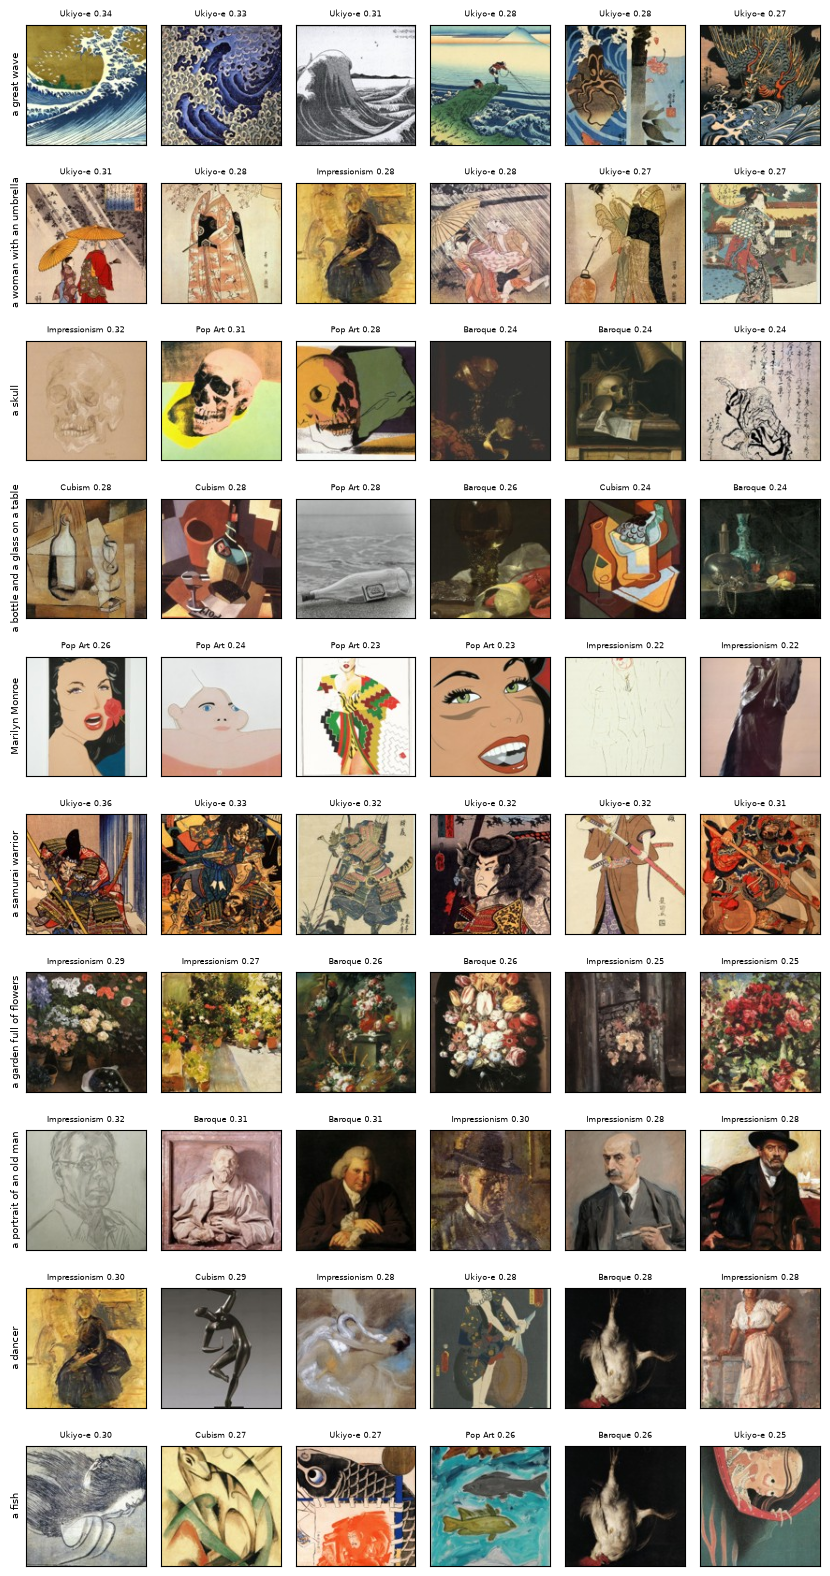

In [5]:
QUERIES = ["a great wave", "a woman with an umbrella", "a skull", "a bottle and a glass on a table", "Marilyn Monroe",
           "a samurai warrior", "a garden full of flowers", "a portrait of an old man", "a dancer", "a fish"]
OUTSIDE = ["a motorbike", "a giraffe", "a nuclear power plant", "an astronaut", "a video game", "a submarine"]


def show_queries(queries, path, k=6):
    fig, axes = plt.subplots(len(queries), k, figsize=(1.4 * k, 1.6 * len(queries)))
    for row, query in zip(axes, queries, strict=True):
        for ax, work in zip(row, collection.search(query, k).itertuples(), strict=True):
            ax.imshow(Image.open(IMAGE_DIR / work.path))
            ax.set_title(f"{DISPLAY_NAMES.get(work.label, work.label)} {work.score:.2f}", fontsize=6)
            ax.set_xticks([])
            ax.set_yticks([])
        row[0].set_ylabel(query, fontsize=7)
    fig.tight_layout()
    fig.savefig(path, dpi=110, bbox_inches="tight")
    return fig


show_queries(QUERIES, FIG_DIR / "09_content_queries.png")
plt.show()

**Judged by eye** (how many of the 6 results show what was asked):

| query | shows it | comment |
|---|---|---|
| a great wave | 5 | three versions of Hokusai's wave come first |
| a woman with an umbrella | 2 | all 6 are women, only 2 have an umbrella |
| a skull | 4 | Warhol-like skulls and a Baroque vanitas |
| a bottle and a glass on a table | 5 | one bottle is floating in the sea |
| Marilyn Monroe | 0 | Pop Art women's faces, but not her |
| a samurai warrior | 6 | |
| a garden full of flowers | 6 | flowers every time, but mostly bouquets, not gardens |
| a portrait of an old man | 6 | |
| a dancer | 2 | a dancing statue, a ballerina, then people standing |
| a fish | 3 | a carp kite, fish in water, and a dead bird |

- **It works well for things with a typical look**: waves, armour, flowers, faces, still lifes.
- **It works badly for an action** (a dancer), **a small detail** (the umbrella) **or a precise person.** For Marilyn Monroe it finds Pop Art women: it matches the kind of image the name suggests rather than the person. We don't know whether our Pop Art images include her at all.
- **The similarities are low in absolute terms** (0.22–0.36). That's normal for CLIP: a text and an image are never as close as two images. Only the order of the results matters.

## 4. Queries the collection can't answer

What happens when the visitor asks for something our five styles almost certainly don't have? Search always returns the 6 closest works, so the question is whether the similarity tells us that they are poor matches.

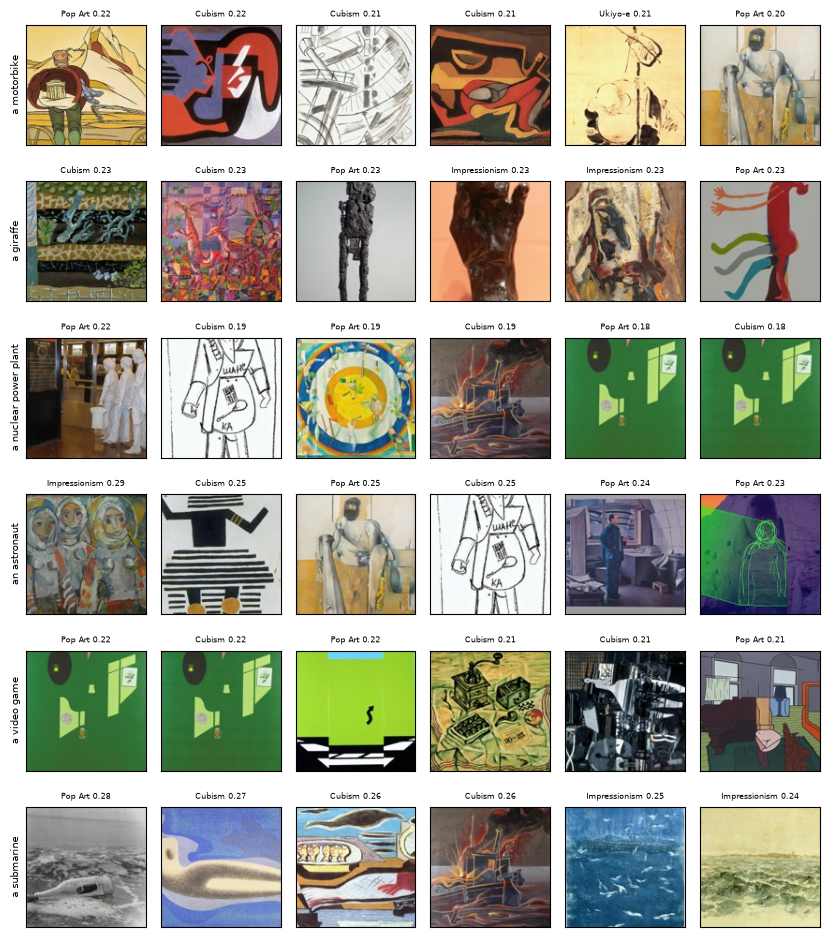

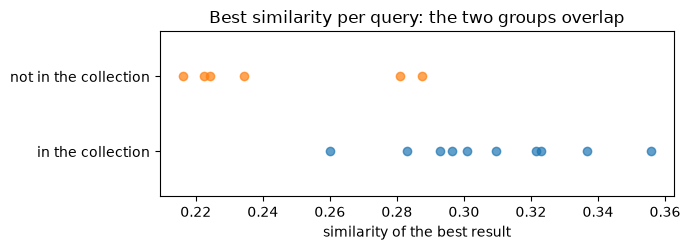

,min,median,max
kind,,,
in the collection,0.260,0.305,0.356
not in the collection,0.216,0.229,0.288


In [6]:
show_queries(OUTSIDE, FIG_DIR / "09_outside_queries.png")
plt.show()

top1 = pd.DataFrame([{"query": q, "kind": kind, "best similarity": collection.search(q, 1)["score"].iloc[0]}
                     for kind, queries in [("in the collection", QUERIES), ("not in the collection", OUTSIDE)]
                     for q in queries])
fig, ax = plt.subplots(figsize=(7, 2.6))
for y, (_kind, group) in enumerate(top1.groupby("kind", sort=False)):
    ax.scatter(group["best similarity"], np.full(len(group), y), alpha=0.7)
ax.set(yticks=[0, 1], yticklabels=top1["kind"].unique(), xlabel="similarity of the best result",
       ylim=(-0.6, 1.6), title="Best similarity per query: the two groups overlap")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_query_scores.png", dpi=150, bbox_inches="tight")
plt.show()
top1.groupby("kind")["best similarity"].agg(["min", "median", "max"]).round(3)

**What we see**
- **The search always returns 6 works, and they're often sensible neighbours**: the sea and a bottle in the waves for "a submarine", figures in helmets for "an astronaut", flat green screens for "a video game".
- **The best similarity is lower on average** (median 0.23 against 0.31), **but the two groups overlap**: "a submarine" (0.28) is above "Marilyn Monroe" (0.26). On the 25 queries we used while writing the code it was worse: "a robot" got 0.28 and "an actor on stage" 0.24.
- **So there's no "not sure" threshold for the search**, unlike the guide. The reply always says "the closest works", never "here is a submarine".
- **The same green picture shows up twice, once as Pop Art and once as Cubism.** It's one of the two cross-style copies that the near-duplicate check found (`results/near_duplicates.csv`), both in train.

## 5. The chat reply

Both writers get the same facts (`chat.facts`): the works found, best first, with style, artist and genre when known, the style counts, and the period of the main style from `stories.md`.

- **The template** fills fixed sentences, so it can't invent anything.
- **The language model** (`Qwen2.5-0.5B-Instruct`, run locally) writes a friendlier reply. It gets rules plus one worked example, and greedy decoding, so the same question always gets the same reply.
- **The check** (`chat.check_reply`) flags what the reply says that the facts don't: a capitalised word that isn't in the facts (a name, a title, a place), an artist put with the wrong style, a style or a number that isn't in the facts, a wrong count, "unknown artist" when the results know one, a list, a refusal. If anything is flagged, the visitor gets the template instead.

The prompt and the check were set up on the other 25 queries. Here they're used as they are, on the 16 queries above.

In [7]:
llm = LLMReplier()
chat_queries = (QUERIES + OUTSIDE)[:3] if FAST_RUN else QUERIES + OUTSIDE
rows = []
for query in chat_queries:
    found = collection.search(query, 6)
    start = time.perf_counter()
    draft = llm(query, found)
    rows.append({"query": query, "seconds": time.perf_counter() - start, "draft": draft,
                 "problems": check_reply(draft, query, found), "template": template_reply(query, found),
                 "template problems": check_reply(template_reply(query, found), query, found)})
replies = pd.DataFrame(rows)
for r in replies.itertuples():
    print(f"* {r.query}\n  template:       {r.template}\n  language model: {r.draft}\n"
          f"  check:          {'; '.join(r.problems) or 'nothing flagged'}\n")
flagged = replies["problems"].map(bool)
print(f"language model replies flagged: {flagged.sum()} of {len(replies)} | template replies flagged: "
      f"{replies['template problems'].map(bool).sum()} | median {replies['seconds'].median():.1f} s per reply")

* a great wave
  template:       Here are the 6 works that look closest to "a great wave": 6 Ukiyo-e. The closest one is by an unknown artist (Ukiyo-e). Among the others: Katsushika Hokusai (Ukiyo-e). Ukiyo-e: 17th to 19th century, in Japan (Edo period).
  language model: These are the closest works I found, not exact matches: six Ukiyo-e prints by unknown artists. Ukiyo-e was created during the Edo period in Japan, around the 17th to 19th centuries.
  check:          says the artist is unknown, but doesn't name Katsushika Hokusai

* a woman with an umbrella
  template:       Here are the 6 works that look closest to "a woman with an umbrella": 5 Ukiyo-e and 1 Impressionism. The closest one is by Utagawa Kuniyoshi (Ukiyo-e). Ukiyo-e: 17th to 19th century, in Japan (Edo period).
  language model: These are the closest works I found, not exact matches: five Ukiyo-e paintings by unknown artists and one Impressionism painting by unknown artist. Ukiyo-e was created during the Edo period in 

**Reading the 16 replies.** We checked every language-model reply against its facts by hand.

| | replies |
|---|---|
| flagged by the check, with a real mistake | 8 |
| flagged by the check, but true ("US" for "United States") | 1 |
| not flagged and right | 4 |
| not flagged but wrong | 3 |

- **The language model gets 11 of the 16 replies wrong.**
  - **Wrong counts:** "one Baroque" when there are two.
  - **"By unknown artists" when the results do name one:** Hokusai, Kuniyoshi, Gris.
  - **Facts from its own memory that we never gave it:** "London", or "the Edo period (1603-1868), a time when both Ukiyo-e and Cubism were active", which is false.
  - **One artist for several works:** three Cubism works "by Georges Braque" when only one is his.
  - **While we were setting it up**, it also invented painters who weren't in the results (Rembrandt, Andy Warhol) and put the works in the Louvre.
- **The check catches 8 of the 11.** The 3 it misses need to understand the sentence:
  - "one by Ukiyo-e" uses a style as if it were an artist
  - "three Cubism sketches" when only one is a sketch
  - the Braque one above
- **The template is never flagged.** Reading it, it's always right, but stiff.
- **So:** with the fallback, a visitor would get the template 9 times out of 16, and 3 of the 7 language-model replies they'd still see are wrong. For a museum that's not acceptable. The template stays the default, and the language model only runs with `--llm`.

In [8]:
query = "a great wave"
answer = reply(query, collection.search(query, 6), llm)
print(f"shown to the visitor ({answer.writer}): {answer.text}")
if answer.rejected:
    print(f"\nlanguage model draft, not shown: {answer.rejected}\nbecause: {'; '.join(answer.problems)}")

shown to the visitor (template): Here are the 6 works that look closest to "a great wave": 6 Ukiyo-e. The closest one is by an unknown artist (Ukiyo-e). Among the others: Katsushika Hokusai (Ukiyo-e). Ukiyo-e: 17th to 19th century, in Japan (Edo period).

language model draft, not shown: These are the closest works I found, not exact matches: six Ukiyo-e prints by unknown artists. Ukiyo-e was created during the Edo period in Japan, around the 17th to 19th centuries.
because: says the artist is unknown, but doesn't name Katsushika Hokusai


## 6. Cost against the director's criteria

The same rules as the four candidates: one CPU thread, batch of 1, float32 sizes, at most 40 ms and 100 MB.

At the kiosk, the collection's embeddings are computed once in advance (1,275 x 512 floats, 2.6 MB), so a query only needs the **text tower**. The **image tower** is needed only to add new works, or to search with a photo.

In [9]:
clip = encoder.model
X_val, _ = get_arrays(128, "val")
runs = 3 if FAST_RUN else 30
found = collection.search("a great wave", 6)
parts = {
    "CLIP text tower (a search)": ([clip.text_model, clip.text_projection],
                                   lambda q: collection.search(q, 6), "a great wave", runs),
    "CLIP image tower (one new image)": ([clip.vision_model, clip.visual_projection],
                                         lambda image: encoder.encode_images(image[None]), X_val[0], runs),
    f"language model reply ({LLM_ID.split('/')[1]})": ([llm.model], lambda q: llm(q, found), "a great wave",
                                                       1 if FAST_RUN else 3),
}
rows = []
for name, (modules, run, sample, n) in parts.items():
    n_params = sum(total_parameters(m) for m in modules)
    timing = benchmark_latency(run, sample, n_threads=1, warmup=1, runs=n)
    rows.append({"part": name, "parameters (M)": n_params / 1e6, "size MB (float32)": n_params * 4 / 1e6,
                 "1 thread, median ms": timing["median_ms"]})
rows.append({"part": "fine-tuned ResNet18 (the guide's model)", "parameters (M)": resnet["n_params"] / 1e6,
             "size MB (float32)": resnet["size_mb"], "1 thread, median ms": resnet["latency_ms"]["threads_1"]["median_ms"]})
cost = pd.DataFrame(rows).set_index("part")
cost["<= 100 MB"] = cost["size MB (float32)"] <= 100
cost["<= 40 ms"] = cost["1 thread, median ms"] <= 40
cost.round(1)

,parameters (M),size MB (float32),"1 thread, median ms",<= 100 MB,<= 40 ms
part,,,,,
CLIP text tower (a search),63.4,253.7,5.4,False,True
CLIP image tower (one new image),87.8,351.4,17.1,False,True
language model reply (Qwen2.5-0.5B-Instruct),494.0,1976.1,1793.5,False,False
fine-tuned ResNet18 (the guide's model),11.2,44.8,16.6,True,True


**What we see**
- **Search is fast but too big.** A query takes about 5 ms on one thread (text tower + 1,275 dot products). But the text tower alone is 254 MB, 2.5 times the budget. Adding a new image takes about 17 ms, but that tower is 351 MB.
- **The language model is far off on both criteria:** about 2 GB, and about 1.8 s per reply on one thread, around 45 times the latency budget.
- **The fine-tuned ResNet18 (44.8 MB, 16.6 ms) is still the only part that fits the kiosk.**
- **To make search fit**, we would try storing the text tower in 8-bit integers (about 64 MB), or running the search on a museum server instead of the kiosk. We didn't test either.

## Summary

- **Search works with no training on our data.** Zero-shot CLIP recognises our five styles about as well as our fine-tuned ResNet on validation (84–88 % against 86 %), with the caveats of section 1. Searching for a style finds the right style every time, and content queries work for things with a typical look.
- **The search can't say "we don't have that"**: good and bad matches get overlapping similarities. So the reply always talks about "the closest works".
- **The chat reply should be the template.** The small language model reads better but got 11 of 16 replies wrong, and our check misses some of them.
- **None of it fits the kiosk budget:** 254 MB for the text tower alone, about 2 GB for the language model. This part is a demo for the questions, not a change to our recommendation. The guide stays the fine-tuned ResNet with its "not sure" answer.

Try it: `python -m museum.chat "a stormy sea"`, and add `--llm` to see the language model's reply (checked, with the template as fallback).